# Hedging a Bank's Interest-Rate Risk: Swap Notionals on the Frontier between Net-Interest-Income-at-Risk and Economic-Value-at-Risk for the Colombian Banking System and a UK Bank, under Basel Shocks and Historical Scenarios

A bank's treasury can hedge interest-rate risk in two currencies of account: earnings (net interest income over the next year) and value (the present value of all its assets minus all its liabilities). The two pull in opposite directions. A bank funded with sticky deposits and lending at fixed rates loses economic value when rates rise, so it would pay fixed on swaps; but paying fixed raises the cost of the hedge when rates fall and makes next year's income more sensitive to rate cuts. Basel's standards on interest-rate risk in the banking book (IRRBB) ask banks to measure both, under six prescribed shocks, and supervisors flag banks whose economic value would fall by more than 15% of Tier 1 capital.

This notebook builds the trade-off explicitly. It takes the balance sheet of the whole Colombian banking system from the supervisory accounts and a stylised UK retail bank, maps them to repricing buckets, measures earnings-at-risk and economic-value-at-risk under the Basel shocks and thousands of historical curve scenarios, and finds the overnight-index-swap (OIS) notionals by tenor that minimise any mix of the two risks, tracing the efficient frontier between them.

**What it does.**

1. It downloads the Colombian banking system's balance sheet (latest month) from the supervisory accounts, today's peso curve (IBR and TES zero-coupon rates) and its history from Banco de la República, and the Bank of England's SONIA OIS curve and history.
2. It assigns every balance-sheet line a repricing profile (contractual for loans and term deposits, behavioural for savings and current accounts) and computes repricing gaps, the change in economic value of equity (ΔEVE) and the change in twelve-month net interest income (ΔNII) under the six Basel shocks.
3. It generates rate scenarios by bootstrapping twelve-month changes of each curve since 2016 in blocks of three months, and measures EVE-at-risk and NII-at-risk as expected shortfalls at 95%.
4. It solves a linear programme for the OIS notionals at five tenors that minimise a weighted mix of the two expected shortfalls, traces the frontier from "protect value" to "protect income", and tests the chosen hedges against the Basel shocks and the supervisory outlier test.

**Data.** Superintendencia Financiera de Colombia via datos.gov.co (*CUIF por moneda*, mxk5-ce6w); Banco de la República (policy rate, IBR, TES zero-coupon rates); Bank of England (SONIA OIS curve).

**Methods.** Repricing-gap analysis, cash-flow discounting for EVE, twelve-month NII simulation, Basel IRRBB shock scenarios, block bootstrap of curve changes, expected shortfall, linear programming (Rockafellar–Uryasev), efficient-frontier analysis.

**Key output.** Repricing gaps, ΔEVE and ΔNII of both banks under every Basel shock; their EVE-at-risk and NII-at-risk; the optimal swap notionals along the frontier; and how far each hedge reduces one risk at the cost of the other.

## 1. Two measures of the same risk

**Economic value of equity (EVE).** Each balance-sheet line is a cash flow at its repricing date: principal plus interest at today's rate for that tenor. ΔEVE is the change in the present value of assets minus liabilities when the zero curve moves from *z*(τ) to *z*(τ) + Δ*z*(τ). Equity has no maturity and is excluded, as the Basel standard requires.

**Net interest income (NII).** With a constant balance sheet, a line that reprices at τ < 1 year earns (or pays) the new rate for the remaining 1 − τ of the year, so ΔNII = Σ ± *B* Δ*z*(τ) (1 − τ). Lines that reprice beyond a year do not change this year's income.

**Swaps.** A receive-fixed OIS of notional *N* and tenor *T* behaves like a fixed-rate asset maturing at *T* funded by a floating liability repricing every quarter: it gains value when rates fall and loses income when short rates rise. Its ΔEVE and ΔNII are linear in *N*, so the hedged bank's risks in every scenario are linear in the notionals.

**Optimisation.** With *S* scenarios, losses *L*<sub>EVE</sub>(*n*) and *L*<sub>NII</sub>(*n*) are linear in the notional vector *n*; expected shortfall at 95% is convex and can be written as a linear programme (Rockafellar and Uryasev, 2000). Minimising *w* ES<sub>NII</sub> + (1 − *w*) ES<sub>EVE</sub> for *w* from 0 to 1 traces the frontier.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import certifi
from scipy.optimize import linprog

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2024
rng = np.random.default_rng(SEED)
SOCRATA = "https://www.datos.gov.co/resource/mxk5-ce6w.json"
BANREP = "https://suameca.banrep.gov.co/graficador-series/rest/graficadorService/consultaSerieParaGraficar?idSerie={}"
BANREP_SERIES = {
    "ibr_on": 241,
    "ibr_1m": 242,
    "ibr_3m": 243,
    "ibr_6m": 16560,
    "tes_1y": 15272,
    "tes_5y": 15273,
    "tes_10y": 15274,
}
COP_T = {
    "ibr_on": 1 / 365,
    "ibr_1m": 1 / 12,
    "ibr_3m": 0.25,
    "ibr_6m": 0.5,
    "tes_1y": 1.0,
    "tes_5y": 5.0,
    "tes_10y": 10.0,
}
BOE_OIS = "https://www.bankofengland.co.uk/-/media/boe/files/statistics/yield-curves/oisddata.zip"
GBP_T = [1 / 12, 0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20]
HEDGE_TENORS = [1, 2, 3, 5, 10]
N_SCEN, HORIZON_M, ALPHA = 5_000, 12, 0.95
# Basel IRRBB shock sizes (bp): parallel, short, long. Sterling from the Basel
# table; the peso is not in the table and is set at the upper end of the
# emerging-market calibrations.
SHOCKS = {"COP": (400, 500, 300), "GBP": (250, 300, 150)}
# supervisory outlier test: ΔEVE worse than 15% of Tier 1
OUTLIER = 0.15
# gross swap notional limited to three times equity
GROSS = 3.0
# hedging cost: 1 bp a year of notional (bid-ask and capital), charged on
# |notional| × tenor
COST_BP = 1.0

print(f"run on {dt.date.today():%Y-%m-%d}")

run on 2026-11-05


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data: balance sheets and curves

**Colombian system bank.** All establecimientos bancarios added up, latest month, all currencies. **UK bank.** A stylised retail bank of £100 billion with a typical UK structure (large fixed-rate mortgage book, sight and savings deposits, some wholesale funding); there is no public line-by-line UK equivalent of the Colombian supervisory accounts, so its shares are illustrative.

Banco de la República's server omits an intermediate certificate from its chain; the public certificate is shipped in `certs/` and added to the trusted bundle (verification stays on).

In [3]:
ACC = {
    "110000": "cash",
    "120000": "money_market",
    "130000": "investments",
    "140400": "mortgage",
    "140800": "consumer",
    "141000": "commercial",
    "141200": "microcredit",
    "100000": "assets",
    "210500": "current_acc",
    "210700": "cdt",
    "210800": "savings",
    "210900": "savings_special",
    "212200": "money_market_liab",
    "212500": "money_market_liab",
    "213000": "bonds",
    "240000": "bank_loans",
    "300000": "equity",
}


def fetch_cuif():
    acc = ",".join(f"'{a}'" for a in ACC)
    last = requests.get(
        SOCRATA,
        params={
            "$select": "max(fecha_corte) as m",
            "$where": "tipo_entidad='1'",
        },
        timeout=300,
    ).json()[0]["m"]
    r = requests.get(
        SOCRATA,
        params={
            "$select": "fecha_corte, codigo_entidad, cuenta, valor",
            "$limit": 50_000,
            "$where": (
                f"tipo_entidad='1' AND moneda='0' AND fecha_corte='{last}' AND"
                f" cuenta in({acc})"
            ),
        },
        timeout=300,
    )
    r.raise_for_status()
    return pd.DataFrame(r.json())


BUNDLE = DATA_DIR / "ca_bundle_banrep.pem"
BUNDLE.write_text(
    Path(os.environ.get("REQUESTS_CA_BUNDLE") or certifi.where()).read_text()
    + "\n"
    + (PROJECT_DIR / "certs" / "geotrust_ev_rsa_ca_g2.pem").read_text()
)


def fetch_banrep():
    out = {}
    for name, sid in BANREP_SERIES.items():
        r = requests.get(
            BANREP.format(sid),
            timeout=120,
            verify=str(BUNDLE),
            headers=BROWSER_HEADERS,
        )
        r.raise_for_status()
        out[name] = pd.Series(
            {
                pd.to_datetime(t, unit="ms").normalize(): v
                for t, v in r.json()[0]["data"]
            },
            dtype=float,
        )
    return pd.DataFrame(out).sort_index()


def fetch_ois():
    r = requests.get(BOE_OIS, timeout=300, headers=BROWSER_HEADERS)
    r.raise_for_status()
    frames = []
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        for f in sorted(n for n in z.namelist() if n.endswith(".xlsx")):
            names = pd.ExcelFile(z.open(f)).sheet_names
            for sh in [
                s
                for s in [
                    "3. spot, short end",
                    "4. spot curve",
                    "2. spot curve",
                ]
                if s in names
            ]:
                raw = pd.read_excel(z.open(f), sheet_name=sh, header=None)
                body = raw.iloc[4:]
                body = body[pd.to_datetime(body[0], errors="coerce").notna()]
                frames.append(
                    pd.DataFrame(
                        body.iloc[:, 1:].to_numpy(float),
                        index=pd.to_datetime(body[0]),
                        columns=np.round(raw.iloc[3, 1:].to_numpy(float), 4),
                    )
                )
    d = pd.concat(frames)
    d = d.T.groupby(level=0).first().T.sort_index(axis=1).sort_index()
    d.columns = [str(c) for c in d.columns]
    return d.resample("ME").last()


CUIF = cached("cuif_banks_latest", fetch_cuif, max_age_hours=24 * 7)
RAW = cached("banrep_rates_daily", fetch_banrep, max_age_hours=24)
OISM = cached("boe_ois_month_end", fetch_ois, max_age_hours=24 * 7)

CUIF["valor"] = pd.to_numeric(CUIF["valor"])
CUIF = CUIF.drop_duplicates(["codigo_entidad", "fecha_corte", "cuenta"])
# COP trillion
SYS = (
    CUIF.assign(line=CUIF["cuenta"].map(ACC)).groupby("line")["valor"].sum()
    / 1e12
)
SYS = SYS.reindex(list(dict.fromkeys(ACC.values()))).fillna(0)
AS_OF = pd.to_datetime(CUIF["fecha_corte"].iloc[0])

# curves: continuously compounded zero rates (decimal), month-end
M = RAW[list(BANREP_SERIES)].resample("ME").last().dropna()
COPZ = pd.DataFrame({
    t: (
        np.log1p(M[k] / 100 * max(round(t * 365), 1) / 360)
        * 365
        / max(round(t * 365), 1)
        if k.startswith("ibr")
        else np.log1p(M[k] / 100)
    )
    for k, t in COP_T.items()
})
GBPZ = (
    OISM[[str(float(round(t, 4))) for t in GBP_T]]
    .dropna()
    .set_axis(GBP_T, axis=1)
    / 100
)
print(
    f"Colombian banks at {AS_OF:%B %Y}: assets COP {SYS['assets']:,.0f}"
    f" trillion, equity {SYS['equity']:,.0f} · peso curve"
    f" {COPZ.index.min():%Y-%m}–{COPZ.index.max():%Y-%m} · SONIA curve"
    f" {GBPZ.index.min():%Y-%m}–{GBPZ.index.max():%Y-%m}"
)

Colombian banks at August 2026: assets COP 1,126 trillion, equity 102 · peso curve 2016-05–2026-10 · SONIA curve 2016-01–2026-10


## 4. Repricing profiles

Each line is split into repricing slices (time in years, share of the line). Loans and term deposits follow typical contractual terms; savings and current accounts follow behavioural assumptions: a volatile share reprices overnight and a stable core is spread over several years, within the caps of the Basel standard (at most about five years on average for retail core deposits). The same profile families are used for both banks so that differences come from balance-sheet structure and curves.

In [4]:
COP_PROFILE = {  # line: (side, [(repricing time in years, share), ...])
    "cash": (+1, [(1 / 365, 1.0)]),
    "money_market": (+1, [(1 / 365, 1.0)]),
    "investments": (+1, [(0.5, 0.2), (2, 0.3), (5, 0.3), (10, 0.2)]),
    "commercial": (+1, [(0.25, 0.5), (1, 0.2), (3, 0.3)]),
    "consumer": (+1, [(0.25, 0.15), (1, 0.25), (2, 0.3), (4, 0.3)]),
    "mortgage": (+1, [(1, 0.1), (5, 0.3), (10, 0.6)]),
    "microcredit": (+1, [(1, 0.6), (2, 0.4)]),
    "current_acc": (-1, [(1 / 365, 0.3), (1, 0.2), (3, 0.3), (5, 0.2)]),
    "savings": (-1, [(1 / 365, 0.3), (1, 0.2), (3, 0.3), (5, 0.2)]),
    "savings_special": (-1, [(1 / 365, 0.3), (1, 0.2), (3, 0.3), (5, 0.2)]),
    "cdt": (-1, [(0.25, 0.3), (0.5, 0.3), (1, 0.3), (2, 0.1)]),
    "money_market_liab": (-1, [(1 / 365, 1.0)]),
    "bonds": (-1, [(2, 0.3), (5, 0.5), (10, 0.2)]),
    "bank_loans": (-1, [(0.5, 0.5), (2, 0.5)]),
}
GBP_BS = {
    "cash": 15,
    "investments": 12,
    "mortgage": 50,
    "commercial": 15,
    "current_acc": 35,
    "savings": 30,
    "money_market_liab": 15,
    "bonds": 10,
    "equity": 7,
}
GBP_PROFILE = {
    "cash": (+1, [(1 / 365, 1.0)]),
    "investments": (+1, [(1, 0.2), (3, 0.3), (5, 0.3), (10, 0.2)]),
    "mortgage": (+1, [(1 / 365, 0.15), (2, 0.6), (5, 0.25)]),
    "commercial": (+1, [(0.25, 0.8), (3, 0.2)]),
    "current_acc": (-1, [(1 / 365, 0.3), (1, 0.2), (3, 0.3), (5, 0.2)]),
    "savings": (-1, [(1 / 365, 0.3), (0.5, 0.3), (1, 0.4)]),
    "money_market_liab": (-1, [(0.25, 1.0)]),
    "bonds": (-1, [(3, 0.5), (5, 0.5)]),
}


def slices(bs, prof):
    rows = []
    for line, (side, prof_) in prof.items():
        for t, sh in prof_:
            rows.append({
                "line": line,
                "side": side,
                "t": t,
                "amount": bs.get(line, 0) * sh,
            })
    return pd.DataFrame(rows)


BANKS = {
    "Colombian banking system (COP tn)": (
        slices(SYS.to_dict(), COP_PROFILE),
        SYS["equity"],
        COPZ,
    ),
    "Stylised UK bank (GBP bn)": (
        slices(GBP_BS, GBP_PROFILE),
        GBP_BS["equity"],
        GBPZ,
    ),
}
EDGES = [0, 1 / 12, 0.25, 0.5, 1, 2, 3, 5, 7, 10, 30]
LABELS = [
    "≤1m",
    "1–3m",
    "3–6m",
    "6–12m",
    "1–2y",
    "2–3y",
    "3–5y",
    "5–7y",
    "7–10y",
    ">10y",
]
GAPS = {}
for name, (S, eq, _) in BANKS.items():
    S["bucket"] = pd.cut(
        S["t"], EDGES, labels=LABELS, right=True, include_lowest=True
    )
    g = (
        S.assign(net=S["side"] * S["amount"])
        .groupby("bucket", observed=False)["net"]
        .sum()
    )
    GAPS[name] = g
GAPT = pd.DataFrame(GAPS)
GAPT.loc["cumulative ≤1y"] = GAPT.iloc[:4].sum()
GAPT.style.format("{:,.1f}").set_caption(
    "Repricing gap (assets − liabilities) by bucket"
)

,Colombian banking system (COP tn),Stylised UK bank (GBP bn)
bucket,,
≤1m,-84.3,3.0
1–3m,127.0,-3.0
3–6m,-79.8,-9.0
6–12m,-31.0,-16.6
1–2y,77.8,30.0
2–3y,-14.1,-8.9
3–5y,73.7,4.1
5–7y,0.0,0.0
7–10y,121.6,2.4


## 5. Basel shocks and historical scenarios

**Basel shocks.** Parallel up and down, short-rate up and down, steepener and flattener, using the standard's shape functions with a short-rate decay of four years. **Historical scenarios.** For each curve, twelve-month scenarios are built by summing twelve monthly changes of the whole curve since 2016, drawn in blocks of three consecutive months to keep the momentum of rate cycles (5,000 scenarios). Scenario changes are applied to today's curve with a floor of zero.

In [5]:
def basel(t, par, short, long_):
    s = np.exp(-np.asarray(t) / 4)
    l = 1 - s
    return {
        "parallel up": par + 0 * s,
        "parallel down": -par + 0 * s,
        "short up": short * s,
        "short down": -short * s,
        "steepener": -0.65 * short * s + 0.9 * long_ * l,
        "flattener": 0.8 * short * s - 0.6 * long_ * l,
    }


def curve_fn(nodes_t, z):
    return lambda s: np.interp(s, nodes_t, z)


def hist_scenarios(Z, n=N_SCEN, h=HORIZON_M, block=3, seed=SEED):
    """
    Twelve-month scenarios: sums of monthly curve changes (all tenors jointly)
    drawn in 3-month blocks since 2016.
    """
    dZ = Z.loc["2016":].diff().dropna().to_numpy()
    g = np.random.default_rng(seed)
    out = np.zeros((n, Z.shape[1]))
    for i in range(n):
        idx = np.concatenate([
            np.arange(st, st + block)
            for st in g.integers(0, len(dZ) - block, h // block)
        ])
        out[i] = dZ[idx].sum(0)
    # decimal changes at the curve nodes
    return out


def risk(S, z0, nodes_t, dz):
    """
    dz: (S_scen, nodes) changes; returns ΔEVE and ΔNII per scenario for the
    balance sheet.
    """
    t, side, amt = (
        S["t"].to_numpy(),
        S["side"].to_numpy(),
        S["amount"].to_numpy(),
    )
    z_t = np.interp(t, nodes_t, z0)
    cf = amt * np.exp(
        z_t * t
    )  # principal plus interest at today's rate, paid at t
    pv0 = (side * cf * np.exp(-z_t * t)).sum()
    d_t = np.array([np.interp(t, nodes_t, d) for d in dz])
    z1 = np.maximum(z_t + d_t, 0)
    eve = (side * cf * np.exp(-z1 * t)).sum(1) - pv0
    nii = (side * amt * (z1 - z_t) * np.clip(1 - t, 0, None)).sum(1)
    return eve, nii


def swap_risk(z0, nodes_t, dz, T, freq=4):
    """
    Receive-fixed OIS, notional 1: fixed leg at today's par rate, floating leg
    repricing quarterly.
    """
    pay = np.arange(1, int(T * freq) + 1) / freq
    df0 = np.exp(-np.interp(pay, nodes_t, z0) * pay)
    par = (1 - df0[-1]) / (df0.sum() / freq)
    z1 = np.maximum(
        np.interp(pay, nodes_t, z0)[None, :]
        + np.array([np.interp(pay, nodes_t, d) for d in dz]),
        0,
    )
    df1 = np.exp(-z1 * pay)
    # fixed bond minus floating note (worth par)
    eve = par / freq * df1.sum(1) + df1[:, -1] - 1
    q = 0.25
    zq0, zq1 = np.interp(q, nodes_t, z0), np.maximum(
        np.interp(q, nodes_t, z0)
        + np.array([np.interp(q, nodes_t, d) for d in dz]),
        0,
    )
    # floating payments reset after the first quarter
    nii = -(zq1 - zq0) * (1 - q)
    return eve, nii


RES = {}
for name, (S, eq, Z) in BANKS.items():
    nodes_t = np.array(Z.columns, float)
    z0 = Z.iloc[-1].to_numpy()
    cur = "COP" if "Colombian" in name else "GBP"
    B = basel(nodes_t, *SHOCKS[cur])
    dzB = np.array([v / 1e4 for v in B.values()])
    dzH = hist_scenarios(Z)
    eB, nB = risk(S, z0, nodes_t, dzB)
    eH, nH = risk(S, z0, nodes_t, dzH)
    sw = {
        T: (swap_risk(z0, nodes_t, dzB, T), swap_risk(z0, nodes_t, dzH, T))
        for T in HEDGE_TENORS
    }
    RES[name] = dict(
        S=S,
        eq=eq,
        nodes=nodes_t,
        z0=z0,
        basel=list(B),
        eB=eB,
        nB=nB,
        eH=eH,
        nH=nH,
        sw=sw,
        dzH=dzH,
        cur=cur,
    )

es = lambda loss: np.mean(
    np.sort(loss)[-int(np.ceil((1 - ALPHA) * len(loss))) :]
)
BASEL_T = pd.concat(
    {
        n: pd.DataFrame(
            {
                "ΔEVE (% of equity)": r["eB"] / r["eq"] * 100,
                "ΔNII (% of equity)": r["nB"] / r["eq"] * 100,
            },
            index=r["basel"],
        )
        for n, r in RES.items()
    },
    axis=1,
)
HIST_T = pd.DataFrame({
    n: {
        "EVE-at-risk, ES 95% (% of equity)": es(-r["eH"]) / r["eq"] * 100,
        "NII-at-risk, ES 95% (% of equity)": es(-r["nH"]) / r["eq"] * 100,
        "worst Basel ΔEVE (% of equity)": r["eB"].min() / r["eq"] * 100,
        "worst Basel ΔNII (% of equity)": r["nB"].min() / r["eq"] * 100,
        "outlier test breached": r["eB"].min() / r["eq"] < -OUTLIER,
        "12m change of 10y (5y GBP) rate, 5th–95th pct (bp)": (
            "{:.0f} to {:.0f}".format(
                *np.percentile(
                    r["dzH"][:, -1 if r["cur"] == "COP" else 6] * 1e4, [5, 95]
                )
            )
        ),
    }
    for n, r in RES.items()
})
display(BASEL_T.style.format("{:+.1f}").set_caption("Unhedged: Basel shocks"))
HIST_T

,Colombian banking system (COP tn),Stylised UK bank (GBP bn)
"EVE-at-risk, ES 95% (% of equity)",47.42,20.77
"NII-at-risk, ES 95% (% of equity)",1.86,1.53
worst Basel ΔEVE (% of equity),-53.02,-18.46
worst Basel ΔNII (% of equity),-1.45,-1.35
outlier test breached,True,True
"12m change of 10y (5y GBP) rate, 5th–95th pct (bp)",-219 to 290,-99 to 216


## 6. The frontier between protecting value and protecting income

For each weight *w*, the linear programme chooses notionals *n*<sub>*T*</sub> for receive-fixed OIS at 1, 2, 3, 5 and 10 years (negative = pay fixed), with gross notional (the sum of absolute notionals) limited to three times equity, to minimise *w* ES<sub>95</sub>(NII loss) + (1 − *w*) ES<sub>95</sub>(EVE loss) + cost over the historical scenarios. The cost of 1 bp a year of notional (|*n*<sub>*T*</sub>| × *T* × 0.01%) stands for bid-ask spreads and the capital that derivatives consume; without it the programme would build large offsetting positions to fit the scenario set. Expected shortfall is linearised with one auxiliary variable per scenario.

In [6]:
def es_lp(LE, LN, w, bound, cost, gross):
    """
    LE, LN: (S, 1 + k) loss matrices: column 0 = unhedged loss, columns 1.. =
    loss per unit notional.
    cost: (k,) cost per unit of absolute notional. Returns notionals (positive
    = receive fixed).
    """
    S, k = LE.shape[0], LE.shape[1] - 1
    c_ = 1 / ((1 - ALPHA) * S)
    # variables: p (k), m (k) with n = p − m, aE, aN, uE (S), uN (S)
    o = 2 * k
    nv = o + 2 + 2 * S
    c = np.zeros(nv)
    c[:k], c[k:o] = cost, cost
    c[o], c[o + 1] = 1 - w, w
    c[o + 2 : o + 2 + S], c[o + 2 + S :] = (1 - w) * c_, w * c_
    A, b = [], []
    for L, a_i, u0 in [(LE, o, o + 2), (LN, o + 1, o + 2 + S)]:
        blk = np.zeros((S, nv))
        blk[:, :k], blk[:, k:o] = L[:, 1:], -L[:, 1:]
        blk[:, a_i] = -1
        blk[np.arange(S), u0 + np.arange(S)] = -1
        A.append(blk)
        b.append(-L[:, 0])
    g = np.zeros((1, nv))
    # gross notional limit
    g[0, :o] = 1
    A.append(g)
    b.append(np.array([gross]))
    bounds = [(0, bound)] * o + [(None, None)] * 2 + [(0, None)] * (2 * S)
    sol = linprog(
        c,
        A_ub=np.vstack(A),
        b_ub=np.concatenate(b),
        bounds=bounds,
        method="highs",
    )
    return sol.x[:k] - sol.x[k:o]


FRONT, CHOSEN = {}, {}
WEIGHTS = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
for name, r in RES.items():
    LE = np.c_[-r["eH"], np.array([-r["sw"][T][1][0] for T in HEDGE_TENORS]).T]
    LN = np.c_[-r["nH"], np.array([-r["sw"][T][1][1] for T in HEDGE_TENORS]).T]
    rows, sols = [], {}
    for w in WEIGHTS:
        n = es_lp(
            LE,
            LN,
            w,
            bound=GROSS * r["eq"],
            cost=COST_BP / 1e4 * np.array(HEDGE_TENORS, float),
            gross=GROSS * r["eq"],
        )
        lossE, lossN = LE[:, 0] + LE[:, 1:] @ n, LN[:, 0] + LN[:, 1:] @ n
        eB = r["eB"] + np.array([r["sw"][T][0][0] for T in HEDGE_TENORS]).T @ n
        nB = r["nB"] + np.array([r["sw"][T][0][1] for T in HEDGE_TENORS]).T @ n
        rows.append({
            "weight on NII": w,
            "EVE-at-risk (% eq.)": es(lossE) / r["eq"] * 100,
            "NII-at-risk (% eq.)": es(lossN) / r["eq"] * 100,
            "worst Basel ΔEVE (% eq.)": eB.min() / r["eq"] * 100,
            "worst Basel ΔNII (% eq.)": nB.min() / r["eq"] * 100,
            **{
                f"{T}y receive-fixed (× equity)": n[i] / r["eq"]
                for i, T in enumerate(HEDGE_TENORS)
            },
        })
        sols[w] = n
    FRONT[name] = pd.DataFrame(rows).set_index("weight on NII")
    CHOSEN[name] = sols
UNH = {
    n: (es(-r["eH"]) / r["eq"] * 100, es(-r["nH"]) / r["eq"] * 100)
    for n, r in RES.items()
}
for name, f in FRONT.items():
    display(
        f.style.format("{:+.2f}")
        .format(
            {"EVE-at-risk (% eq.)": "{:.1f}", "NII-at-risk (% eq.)": "{:.1f}"}
        )
        .set_caption(
            f"{name}: frontier (unhedged EVE-at-risk {UNH[name][0]:.1f}%,"
            f" NII-at-risk {UNH[name][1]:.1f}% of equity)"
        )
    )

,EVE-at-risk (% eq.),NII-at-risk (% eq.),worst Basel ΔEVE (% eq.),worst Basel ΔNII (% eq.),1y receive-fixed (× equity),2y receive-fixed (× equity),3y receive-fixed (× equity),5y receive-fixed (× equity),10y receive-fixed (× equity)
weight on NII,,,,,,,,,
0.000000,1.3,4.5,-0.921673,-7.412442,0.000000,0.000000,0.236667,0.004859,-2.758474
0.100000,1.3,4.5,-0.918055,-7.396447,0.000000,0.000000,0.243796,0.000000,-2.756204
0.200000,1.3,4.5,-0.929694,-7.384028,0.000000,0.000000,0.245559,0.000000,-2.754441
0.300000,1.3,4.5,-0.941833,-7.371075,0.000000,0.000000,0.247397,0.000000,-2.752603
0.400000,1.3,4.5,-0.953109,-7.359042,0.000000,0.000000,0.249105,0.000000,-2.750895
0.500000,1.4,4.4,-0.948848,-7.138856,0.000000,0.280357,0.000000,0.000000,-2.719643
0.600000,1.6,4.2,-1.384510,-6.780993,0.331149,0.000000,0.000000,0.000000,-2.668851
0.700000,1.7,4.1,-1.480664,-6.672940,0.346485,0.000000,0.000000,0.000000,-2.653515
0.800000,2.1,4.0,-2.151972,-6.460046,0.376702,0.000000,0.000000,0.000000,-2.623298


,EVE-at-risk (% eq.),NII-at-risk (% eq.),worst Basel ΔEVE (% eq.),worst Basel ΔNII (% eq.),1y receive-fixed (× equity),2y receive-fixed (× equity),3y receive-fixed (× equity),5y receive-fixed (× equity),10y receive-fixed (× equity)
weight on NII,,,,,,,,,
0.000000,0.5,0.6,-1.322085,-2.114568,0.679953,0.000000,-1.719580,-0.131260,-0.469207
0.100000,0.5,0.6,-1.279355,-2.081655,0.687739,0.000000,-1.685947,-0.161989,-0.464325
0.200000,0.5,0.6,-1.226221,-2.033715,0.699079,0.000000,-1.626303,-0.223906,-0.450712
0.300000,0.5,0.5,-1.190661,-1.956343,0.717382,0.000000,-1.531737,-0.317985,-0.432897
0.400000,0.5,0.5,-1.185211,-1.874516,0.736738,0.000000,-1.428020,-0.421777,-0.413465
0.500000,0.6,0.5,-1.182336,-1.756855,0.764571,0.000000,-1.293803,-0.549106,-0.392520
0.600000,0.6,0.4,-1.155529,-1.549555,0.813609,0.000000,-1.050430,-0.785424,-0.350536
0.700000,0.7,0.4,-1.091058,-1.302158,0.872132,0.000000,-0.776756,-1.046426,-0.304687
0.800000,0.9,0.3,-1.063173,-1.001968,0.943143,0.000000,-0.423758,-1.388421,-0.244677


## 7. Three hedges compared

For each bank: no hedge, the hedge that minimises EVE-at-risk (*w* = 0), the hedge that minimises NII-at-risk (*w* = 1) and the balanced hedge (*w* = 0.5), and a simple duration hedge that only neutralises the parallel-shock ΔEVE with a single five-year swap.

In [7]:
CMP = {}
for name, r in RES.items():
    eq = r["eq"]
    swB = lambda n: (
        np.array([r["sw"][T][0][0] for T in HEDGE_TENORS]).T @ n,
        np.array([r["sw"][T][0][1] for T in HEDGE_TENORS]).T @ n,
    )
    swH = lambda n: (
        np.array([r["sw"][T][1][0] for T in HEDGE_TENORS]).T @ n,
        np.array([r["sw"][T][1][1] for T in HEDGE_TENORS]).T @ n,
    )
    i5 = HEDGE_TENORS.index(5)
    n_dur = np.zeros(len(HEDGE_TENORS))
    # offset parallel-up ΔEVE with the 5y swap
    n_dur[i5] = -r["eB"][0] / r["sw"][5][0][0][0]
    cases = {
        "no hedge": np.zeros(len(HEDGE_TENORS)),
        "duration hedge (5y only)": n_dur,
        "min EVE-at-risk": CHOSEN[name][0],
        "balanced (w = 0.5)": CHOSEN[name][0.5],
        "min NII-at-risk": CHOSEN[name][1.0],
    }
    rows = {}
    for k, n in cases.items():
        eB, nB = r["eB"] + swB(n)[0], r["nB"] + swB(n)[1]
        eH, nH = r["eH"] + swH(n)[0], r["nH"] + swH(n)[1]
        rows[k] = {
            "net receive-fixed notional (× equity)": n.sum() / eq,
            "EVE-at-risk (% eq.)": es(-eH) / eq * 100,
            "NII-at-risk (% eq.)": es(-nH) / eq * 100,
            "worst Basel ΔEVE (% eq.)": eB.min() / eq * 100,
            "worst Basel ΔNII (% eq.)": nB.min() / eq * 100,
            "outlier test": (
                "breached" if eB.min() / eq < -OUTLIER else "passed"
            ),
        }
    CMP[name] = pd.DataFrame(rows).T
    display(
        CMP[name]
        .style.format(
            {c: "{:.1f}" for c in CMP[name].columns if c != "outlier test"}
        )
        .set_caption(name)
    )

,net receive-fixed notional (× equity),EVE-at-risk (% eq.),NII-at-risk (% eq.),worst Basel ΔEVE (% eq.),worst Basel ΔNII (% eq.),outlier test
no hedge,0.0,47.4,1.9,-53.0,-1.5,breached
duration hedge (5y only),-3.8,13.7,7.0,-15.1,-12.0,breached
min EVE-at-risk,-2.5,1.3,4.5,-0.9,-7.4,passed
balanced (w = 0.5),-2.4,1.4,4.4,-0.9,-7.1,passed
min NII-at-risk,-0.5,45.8,1.1,-51.2,-0.4,breached


,net receive-fixed notional (× equity),EVE-at-risk (% eq.),NII-at-risk (% eq.),worst Basel ΔEVE (% eq.),worst Basel ΔNII (% eq.),outlier test
no hedge,0.0,20.8,1.5,-18.5,-1.4,breached
duration hedge (5y only),-1.7,1.3,0.6,-1.3,-2.3,passed
min EVE-at-risk,-1.6,0.5,0.6,-1.3,-2.1,passed
balanced (w = 0.5),-1.5,0.6,0.5,-1.2,-1.8,passed
min NII-at-risk,-1.0,18.1,0.3,-16.0,-0.8,breached


## 8. Charts and dashboard

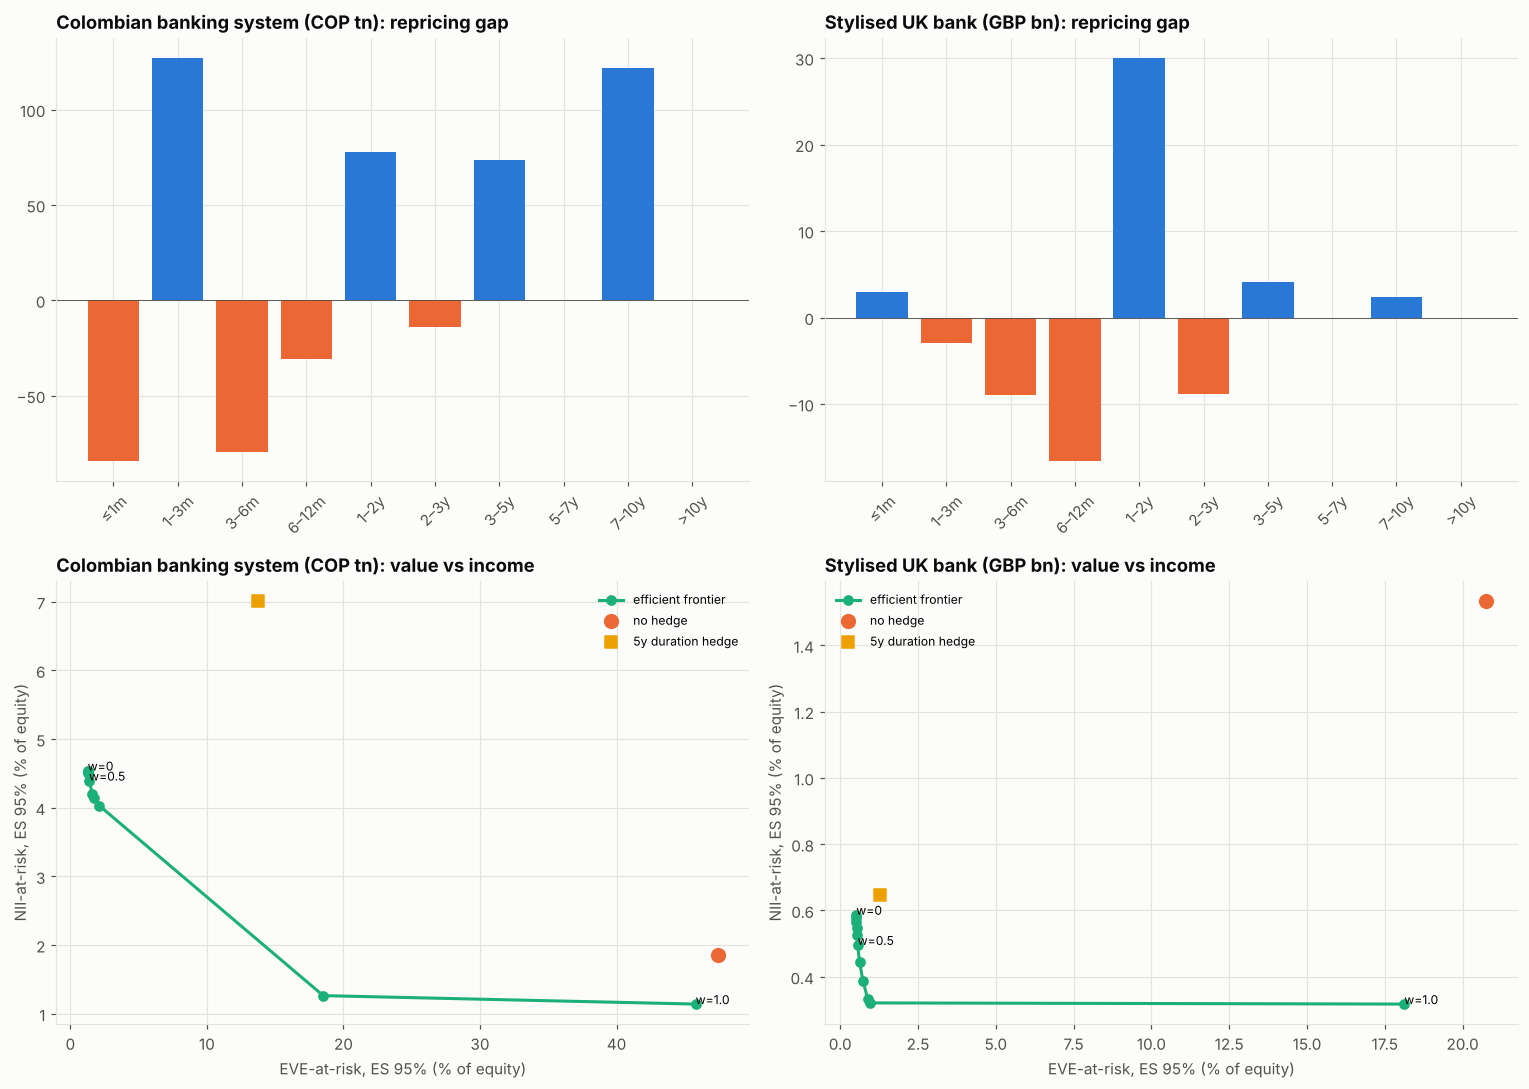

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for j, (name, r) in enumerate(RES.items()):
    a = ax[0, j]
    g = GAPT[name].iloc[:-1]
    a.bar(
        g.index,
        g.values,
        color=[PALETTE[0] if v > 0 else PALETTE[1] for v in g.values],
    )
    a.axhline(0, color=INK_2, lw=0.6)
    a.set_title(f"{name}: repricing gap")
    a.tick_params(axis="x", rotation=45)
    a = ax[1, j]
    f = FRONT[name]
    a.plot(
        f["EVE-at-risk (% eq.)"],
        f["NII-at-risk (% eq.)"],
        marker="o",
        color=PALETTE[2],
        label="efficient frontier",
    )
    for w in [0, 0.5, 1.0]:
        a.annotate(
            f"w={w}",
            (f.loc[w, "EVE-at-risk (% eq.)"], f.loc[w, "NII-at-risk (% eq.)"]),
            fontsize=8,
        )
    a.scatter(*UNH[name], color=PALETTE[1], s=80, zorder=3, label="no hedge")
    d = CMP[name].loc["duration hedge (5y only)"]
    a.scatter(
        d["EVE-at-risk (% eq.)"],
        d["NII-at-risk (% eq.)"],
        color=PALETTE[3],
        marker="s",
        s=60,
        zorder=3,
        label="5y duration hedge",
    )
    a.set_xlabel("EVE-at-risk, ES 95% (% of equity)")
    a.set_ylabel("NII-at-risk, ES 95% (% of equity)")
    a.set_title(f"{name}: value vs income")
    a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_hedge_frontier")
plt.show()

In [9]:
dash = make_subplots(rows=1, cols=2, subplot_titles=list(RES))
for j, name in enumerate(RES):
    b = BASEL_T[name]
    dash.add_trace(
        go.Bar(
            x=b.index,
            y=b["ΔEVE (% of equity)"],
            name="ΔEVE",
            marker_color=PALETTE[0],
            showlegend=j == 0,
        ),
        1,
        j + 1,
    )
    dash.add_trace(
        go.Bar(
            x=b.index,
            y=b["ΔNII (% of equity)"],
            name="ΔNII",
            marker_color=PALETTE[1],
            showlegend=j == 0,
        ),
        1,
        j + 1,
    )
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    title="Unhedged ΔEVE and ΔNII under the Basel shocks (% of equity)",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

*The Colombian figures use the banking system's latest supervisory balance sheet (August 2026) and repricing profiles that are assumptions, not reported data. The UK bank is stylised. Scenarios are seeded.*

**Two balance sheets.**
- **Colombian banking system:** COP 1,126 trillion of assets and COP 102 trillion of equity. CDTs and the volatile part of savings and current accounts reprice within a year, so the cumulative one-year repricing gap is −COP 68 trillion (two-thirds of equity). Mortgages, investments and fixed-rate consumer loans create long asset positions at 1–2, 3–5 and 7–10 years.
- **Stylised UK bank:** a £100 billion bank whose two-year fixed mortgages dominate the 1–2-year bucket and whose savings reprice within a year (one-year gap −£26 billion against £7 billion of equity).

**Unhedged risk.**

| % of equity | Colombian system | UK bank |
|---|---|---|
| Worst Basel ΔEVE (parallel up: 400 bp in pesos, 250 bp in sterling) | −53.0 | −18.5 |
| EVE-at-risk, ES 95%, historical 12-month scenarios | 47.4 | 20.8 |
| Worst Basel ΔNII | −1.5 | −1.4 |
| NII-at-risk, ES 95% | 1.9 | 1.5 |
| Supervisory outlier test (ΔEVE < −15%) | breached | breached |

- **Value is the bigger exposure.** Both banks lose value when rates rise, because long fixed-rate assets are funded with short liabilities. Their net interest income moves little within a year: it falls when rates rise, because deposits reprice first.
- **The peso exposure is extreme mainly because the shocks are.** The historical 90% range for the 12-month change of the ten-year peso rate is −2.2 to +2.9 points, against −1.0 to +2.2 points for the five-year SONIA rate.

**The hedging frontier.**

| Colombian system | EVE-at-risk | NII-at-risk | Worst Basel ΔEVE | Hedge (receive-fixed notional × equity) |
|---|---|---|---|---|
| No hedge | 47.4% | 1.9% | −53.0% | — |
| Single 5-year duration hedge | 13.8% | 7.0% | −15.1% | 5y: −3.8 |
| Minimum EVE-at-risk | 1.3% | 4.5% | −0.9% | 3y: +0.2, 10y: −2.8 |
| Weight 0.9 on NII | 18.5% | 1.3% | −20.7% | 1y: +1.2, 10y: −1.8 |
| Minimum NII-at-risk | 45.8% | 1.1% | −51.2% | 1y: −0.5 |

- **In pesos, value and income pull apart.** Protecting value means paying fixed for ten years on almost three times equity. That neutralises EVE but turns the bank's income against falling rates: NII-at-risk rises from 1.9% to 4.5% of equity, and the worst Basel ΔNII from −1.5% to −7.4%. Moving along the frontier, income risk only falls back below 2% once most of the value hedge is given up.
- **A single five-year swap is a poor compromise.** Sized to offset the parallel shock, it leaves 14% of EVE-at-risk, fails the outlier test under other shocks and raises NII-at-risk to 7%. Using the 3- and 10-year points instead removes almost all EVE risk with less income risk.
- **In sterling, the trade-off is mild.** Paying fixed at three and five years and receiving at one year cut EVE-at-risk from 20.8% to 0.5% and NII-at-risk from 1.5% to 0.6% at the same time. The UK bank's risks sit at shorter tenors that the hedges reach without overshooting.
- **Basel shocks confirm the hedges out of sample.** The hedges were optimised on historical scenarios, yet every frontier hedge with a weight of up to 0.8 on income (0.9 in sterling) passes the 15% outlier test under all six prescribed shocks.

**What this means for a bank treasury.**
- **Choose the point on the frontier explicitly.** Pure EVE immunisation can double or treble earnings volatility. Boards should set limits for both measures and let the treasury pick swap tenors against both, not only against DV01.
- **Use several tenors.** Concentrated duration hedges remove parallel risk but leave curve risk and add income risk.
- **For Colombian banks, the long end is the problem.** Few public long-dated IBR swap quotes exist, and TES-based curves carry sovereign risk. Hedging ten-year exposures is costly and basis-prone, so balance-sheet choices (shorter fixed periods, UVR-indexed lending) may be the cheaper hedge.

**Limitations.**
- **Balance sheet:** repricing profiles are assumptions (contractual terms are not public), the UK bank is stylised, and balances are held constant without prepayment or deposit behaviour that depends on rates.
- **Curves and hedges:** the peso curve uses TES zero-coupon rates beyond one year as a proxy for IBR swaps. Hedges are single-curve OIS with a 1 bp-a-year cost and a gross-notional limit of three times equity. Expected shortfall is estimated on bootstrapped histories since 2016, and the frontier is in-sample.

In [10]:
GAPT.to_csv(OUT_DIR / "repricing_gaps.csv")
BASEL_T.to_csv(OUT_DIR / "basel_shocks_unhedged.csv")
HIST_T.to_csv(OUT_DIR / "historical_risk_unhedged.csv")
pd.concat(FRONT).to_csv(OUT_DIR / "efficient_frontier.csv")
pd.concat(CMP).to_csv(OUT_DIR / "hedges_compared.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_hedge_frontier.png, basel_shocks_unhedged.csv, dashboard.html, dashboard.png, efficient_frontier.csv, hedges_compared.csv, historical_risk_unhedged.csv, repricing_gaps.csv


## References

- Basel Committee on Banking Supervision. (2016). *Standards: Interest rate risk in the banking book*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d368.htm
- Bessis, J. (2015). *Risk management in banking* (4th ed.). Wiley.
- Rockafellar, R. T., & Uryasev, S. (2000). Optimization of conditional value-at-risk. *Journal of Risk*, 2(3), 21–41. https://doi.org/10.21314/JOR.2000.038
- Rockafellar, R. T., & Uryasev, S. (2002). Conditional value-at-risk for general loss distributions. *Journal of Banking & Finance*, 26(7), 1443–1471. https://doi.org/10.1016/S0378-4266(02)00271-6
- Banco de la República. (2026). *Portal de estadísticas económicas* [Data: IBR and TES zero-coupon rates]. https://suameca.banrep.gov.co/estadisticas-economicas/
- Bank of England. (2026). *Yield curves* [Data: OIS (SONIA) curve]. https://www.bankofengland.co.uk/statistics/yield-curves
- Superintendencia Financiera de Colombia. (2026). *Información financiera con fines de supervisión – CUIF por moneda* [Data set]. datos.gov.co. https://www.datos.gov.co